# Competencia 01 — Entrega final

Notebook para reproducir la entrega final de Zulip. Parte del dataset crudo, arma la clase y el feature engineering, entrena los modelos finales con los hiperparámetros que salieron de la optimización bayesiana y deja el archivo con los `numero_de_cliente` a enviar.

**Resumen del modelo**
- Feature engineering: `ccajas_depositos` en NA para 202105 → lag1/delta1 y lag2/delta2 de las variables originales → ranking por mes con cero fijo de todas las variables (originales, lags y deltas), salvo `numero_de_cliente`, `foto_mes` y `clase_ternaria`.
- LightGBM con hiperparámetros fijos.
- 20 modelos finales iguales salvo la semilla (semillas primas fijas), entrenados con 202103 a 202106 completos, sin undersampling.
- Ensamble: se promedian las probabilidades de los modelos por cliente y se ordena de mayor a menor. Se generan archivos con 5, 10, 15 y 20 modelos y cortes de 9.500 a 15.000.
- La entrega final es el ensamble de los 20 modelos cortado en `PARAM$envios` clientes.

## Cómo correrla

**Entorno.** Notebook de R. La corrí en una VM de Google Cloud con 8 vCPU y 64 GB de RAM. Las librerías que falten se instalan.

**Datos crudos.** Copiar `competencia_01_crudo.csv` (también sirve `.csv.gz` o `.zip`) en:

```
~/buckets/b1/datasets/
```

La carpeta `datasets/` tiene que existir. Si se usa otra carpeta base, cambiar solo `carpeta_base` en la celda 0.1.

**Ejecución.** Correr todas las celdas en orden (*Run All*).
- La primera vez genera `datasets/competencia_01.csv.gz` (clase ternaria) y `datasets/competencia_01_fe_naccajas_lag1_delta1_lag2_delta2_rankfinal.fst` (dataset con FE). Si ya existen, los reutiliza.
- Cada modelo guarda su probabilidad apenas termina; si la corrida se corta, al volver a correr sigue desde el que faltaba.

**Archivos para probar en Zulip.** Ensambles de 5, 10, 15 y 20 modelos con cortes de 9.500 a 15.000 de a 500:

```
~/buckets/b1/exp/C1_E012_entrega/zulip_cortes/ens05/<corte>/C1_E012_ens05_c<corte>.csv   (y ens10, ens15, ens20)
```

**Archivo final para Zulip.** Lo genera la sección 3. Queda en:

```
~/buckets/b1/exp/C1_E012_entrega/zulip/C1_E012_ensamble_20S_<envios>.csv
```

## 0. Configuración

### 0.1 Carpetas y librerías

In [1]:
options(repos = c(CRAN = "https://cloud.r-project.org"))

# carpeta base: adentro tienen que estar datasets/ (con el crudo) y se crea exp/
carpeta_base <- path.expand("~/buckets/b1")

carpeta_datasets <- file.path(carpeta_base, "datasets")
if (!dir.exists(carpeta_datasets))
  stop("No existe ", carpeta_datasets, ". Crearla y copiar ahí competencia_01_crudo.csv")

for (paquete in c("data.table", "R.utils", "fst", "yaml", "lightgbm", "primes", "ggplot2")) {
  if (!require(paquete, character.only = TRUE)) {
    install.packages(paquete)
    library(paquete, character.only = TRUE)
  }
}

Loading required package: data.table


Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%


Loading required package: R.utils

Loading required package: R.oo

Loading required package: R.methodsS3

R.methodsS3 v1.8.2 (2022-06-13 22:00:14 UTC) successfully loaded. See ?R.methodsS3 for help.

R.oo v1.27.1 (2025-05-02 21:00:05 UTC) successfully loaded. See ?R.oo for help.


Attaching package: ‘R.oo’


The following object is masked from ‘package:R.methodsS3’:

    throw


The following objects are masked from ‘package:methods’:

    getClasses, getMethods


The following objects are masked from ‘package:base’:

    attach, detach, load, save


R.utils v2.13.0 (2025-02-24 21:20:02 UTC) successfully loaded. See ?R.utils for help.


Attaching package: ‘R.utils’


The following object is masked from ‘package:utils’:

    timestamp


The following objects are masked from ‘package:base’:

    cat, commandArgs, getOption, isOpen, nullfile, parse, u

### 0.2 Parámetros del experimento
Meses, semillas, corte y parámetros fijos de LightGBM. Las semillas son las primeras `n_semillas` de una lista fija de 20 números primos (la misma que usé al experimentar), escrita a mano en la celda.

In [2]:
PARAM <- list()
PARAM$experimento <- "C1_E012_entrega_MH"
PARAM$semilla_primigenia <- 110017

PARAM$train_final <- c(202103, 202104, 202105, 202106)   # entrenamiento de los modelos finales
PARAM$future      <- 202108                              # mes a predecir
PARAM$undersampling <- 1.0                               # sin undersampling

PARAM$train_test  <- c(202103, 202104)                   # test (1.3): entrena
PARAM$test        <- 202106                              #             y mide

PARAM$n_semillas <- 20L                          # modelos finales
PARAM$bloques    <- c(5L, 10L, 15L, 20L)         # ensambles parciales para probar en Zulip
PARAM$cortes     <- seq(9500L, 15000L, by = 500L)

# test en 202106 con las primeras semillas
PARAM$test_n_semillas <- 5L

# hilos de LightGBM
PARAM$num_threads <- 4L

In [3]:
# parametros fijos de LightGBM (los mismos de la BO)
PARAM$lgbm_fijos <- list(
  boosting = "gbdt",
  objective = "binary",
  metric = "auc",
  feature_pre_filter = FALSE,
  first_metric_only = FALSE,
  boost_from_average = TRUE,
  force_row_wise = TRUE,
  deterministic = TRUE,
  verbosity = -100,
  seed = PARAM$semilla_primigenia,
  max_depth = -1L,
  min_gain_to_split = 0,
  lambda_l1 = 0.0,
  lambda_l2 = 0.0,
  max_bin = 31L,
  bagging_fraction = 1.0,
  pos_bagging_fraction = 1.0,
  neg_bagging_fraction = 1.0,
  is_unbalance = FALSE,
  scale_pos_weight = 1.0,
  drop_rate = 0.1,
  max_drop = 50,
  skip_drop = 0.5,
  extra_trees = FALSE,
  early_stopping = 0,
  min_data_in_leaf = 0,
  feature_fraction = 0.50,
  learning_rate = 0.005
)

# 20 semillas FIJAS (numeros primos de 6 cifras), siempre las mismas y en el mismo orden.
# Salen de: set.seed(110017, kind = "L'Ecuyer-CMRG"); sample(primes::generate_primes(100000, 999999), 20)
# Quedan escritas a mano para que no dependan de la version de R ni de ningun paquete.
PARAM$semillas_20 <- c(325229L, 622049L, 450451L, 225637L, 239297L, 219763L, 418981L, 182627L, 248351L, 387199L,
                       982703L, 342929L, 908893L, 793399L, 112249L, 162263L, 347987L, 910849L, 453667L, 122921L)
stopifnot(length(PARAM$semillas_20) == 20L, !anyDuplicated(PARAM$semillas_20))

PARAM$lgbm_fijos$num_threads <- PARAM$num_threads

archivo_clase <- file.path(carpeta_datasets, "competencia_01.csv.gz")
archivo_fe    <- file.path(carpeta_datasets, "competencia_01_fe_naccajas_lag1_delta1_lag2_delta2_rankfinal.fst")
carpeta_exp   <- file.path(carpeta_base, "exp", PARAM$experimento)
dir.create(file.path(carpeta_exp, "probabilidades"), recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(carpeta_exp, "zulip"), recursive = TRUE, showWarnings = FALSE)

### 0.3 Funciones auxiliares
Para no duplicar el dataset en memoria se trabaja con índices de filas y las matrices de LightGBM se arman columna por columna.

In [4]:
# saca filas de un data.table sin tener dos copias completas en memoria
filtrar_filas <- function(dt, filas) {
  cols <- copy(names(dt))
  out <- data.table(.tmp = seq_along(filas))
  for (k in seq_along(cols)) {
    set(out, j = cols[k], value = dt[[cols[k]]][filas])
    set(dt, j = cols[k], value = NULL)
  }
  out[, .tmp := NULL]
  gc(verbose = FALSE)
  out
}

# lee del .fst solo los meses pedidos (el archivo esta ordenado por foto_mes)
leer_meses_fst <- function(archivo, meses) {
  fm <- read_fst(archivo, columns = "foto_mes")$foto_mes
  stopifnot(all(meses %in% fm))
  filas <- which(fm %in% meses)
  dt <- read_fst(archivo, from = min(filas), to = max(filas), as.data.table = TRUE)
  filas <- which(dt$foto_mes %in% meses)
  if (length(filas) < nrow(dt)) dt <- filtrar_filas(dt, filas)
  gc(full = TRUE, verbose = FALSE)
  dt
}

# matriz numerica para LightGBM a partir de un subconjunto de filas y columnas
armar_matriz <- function(dt, filas, campos) {
  m <- matrix(NA_real_, nrow = length(filas), ncol = length(campos), dimnames = list(NULL, campos))
  for (j in seq_along(campos)) m[, j] <- as.numeric(dt[[campos[j]]][filas])
  m
}

# lgb.Dataset con los mismos parametros de dataset en todos los modelos
armar_dtrain <- function(dt, filas, campos) {
  d <- lgb.Dataset(data = armar_matriz(dt, filas, campos), label = dt$clase01[filas],
                   params = list(max_bin = PARAM$lgbm_fijos$max_bin, feature_pre_filter = FALSE,
                                 data_random_seed = PARAM$semilla_primigenia),
                   free_raw_data = TRUE)
  lgb.Dataset.construct(d)
  gc(full = TRUE, verbose = FALSE)
  d
}

# ranking por mes con cero fijo: positivos en (0, 1], negativos en [-1, 0), ceros y NA sin cambios
rank_cero_fijo <- function(x) {
  out <- x
  pos <- !is.na(x) & x > 0
  neg <- !is.na(x) & x < 0
  if (any(pos)) out[pos] <-  frank( x[pos], ties.method = "average") / sum(pos)
  if (any(neg)) out[neg] <- -frank(-x[neg], ties.method = "average") / sum(neg)
  out
}

# csv para Zulip: sin encabezado, solo numero_de_cliente como entero
escribir_zulip <- function(ids, archivo) {
  txt <- formatC(ids, format = "d", big.mark = "")
  stopifnot(!anyDuplicated(txt), all(grepl("^[0-9]+$", txt)))
  con <- file(archivo, open = "wb")
  writeLines(txt, con, sep = "\n")
  close(con)
  stopifnot(identical(readLines(archivo), txt))
  invisible(archivo)
}

# mensaje con hora, por pantalla y al archivo de estado
reportar <- function(...) {
  linea <- paste0("[", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), "] ", paste0(...))
  cat(linea, "\n"); flush.console()
  if (exists("archivo_estado")) cat(linea, "\n", file = archivo_estado, append = TRUE)
  invisible(linea)
}


# 1. Desarrollo

## 1.1 Preprocesamiento
Si el dataset con feature engineering ya existe en `datasets/`, se saltea todo este bloque.

In [5]:
hacer_fe    <- !file.exists(archivo_fe)
hacer_clase <- hacer_fe && !file.exists(archivo_clase)
cat("Generar clase ternaria:", hacer_clase, "| Generar feature engineering:", hacer_fe, "\n")

Generar clase ternaria: FALSE | Generar feature engineering: FALSE 


### Clase ternaria
Para cada cliente y mes se mira si sigue apareciendo en los meses siguientes:
- **BAJA+1**: no está en el mes siguiente.
- **BAJA+2**: está en el mes siguiente pero no en el subsiguiente.
- **CONTINUA**: el resto.

Los dos últimos meses quedan sin clase porque no hay información futura.

In [6]:
if (hacer_clase) {
  crudos <- file.path(carpeta_datasets, paste0("competencia_01_crudo", c(".csv", ".csv.gz", ".zip", ".csv.zip")))
  archivo_crudo <- crudos[file.exists(crudos)][1]
  if (is.na(archivo_crudo)) stop("No encuentro competencia_01_crudo.csv en ", carpeta_datasets)

  if (grepl("\\.zip$", archivo_crudo)) {
    csv_local <- utils::unzip(archivo_crudo, exdir = tempdir())
    dataset <- fread(csv_local[grepl("\\.csv$", csv_local)][1])
    unlink(csv_local)
  } else {
    dataset <- fread(archivo_crudo)
  }

  dsimple <- dataset[, list(pos = .I, numero_de_cliente,
                            periodo0 = as.integer(foto_mes / 100) * 12 + foto_mes %% 100)]
  setorder(dsimple, numero_de_cliente, periodo0)

  periodo_ultimo     <- dsimple[, max(periodo0)]
  periodo_anteultimo <- periodo_ultimo - 1

  dsimple[, c("periodo1", "periodo2") := shift(periodo0, n = 1:2, fill = NA, type = "lead"), numero_de_cliente]

  dsimple[periodo0 < periodo_anteultimo, clase_ternaria := "CONTINUA"]
  dsimple[periodo0 < periodo_ultimo & (is.na(periodo1) | periodo0 + 1 < periodo1),
          clase_ternaria := "BAJA+1"]
  dsimple[periodo0 < periodo_anteultimo & (periodo0 + 1 == periodo1) & (is.na(periodo2) | periodo0 + 2 < periodo2),
          clase_ternaria := "BAJA+2"]

  setorder(dsimple, pos)
  dataset[, clase_ternaria := dsimple$clase_ternaria]
  fwrite(dataset, file = archivo_clase, sep = ",")
  rm(dsimple)
  gc(full = TRUE, verbose = FALSE)

} else if (hacer_fe) {
  dataset <- fread(archivo_clase)
}

if (hacer_fe) print(dataset[, .N, keyby = list(foto_mes, clase_ternaria)])

### Corrección de `ccajas_depositos` en 202105
En 202105 esta variable tiene valores anómalos. La pongo en NA **antes** de calcular los lags para que el problema no se arrastre a los meses siguientes.

In [7]:
if (hacer_fe) {
  dataset[foto_mes == 202105, ccajas_depositos := NA]
  cat("ccajas_depositos en NA para 202105:", dataset[foto_mes == 202105, sum(is.na(ccajas_depositos))], "registros\n")
}

### Lags y deltas de orden 1
Para cada variable numérica se agrega el valor del mes anterior (`_lag1`) y la diferencia con ese mes (`_delta1`). Si el cliente no estaba el mes anterior, quedan en NA.

In [8]:
if (hacer_fe) {
  setorder(dataset, numero_de_cliente, foto_mes)
  cols_orig <- setdiff(names(dataset)[sapply(dataset, is.numeric)], c("numero_de_cliente", "foto_mes", "clase_ternaria"))

  periodo0 <- as.integer(dataset$foto_mes / 100) * 12L + dataset$foto_mes %% 100L
  ok <- dataset$numero_de_cliente == shift(dataset$numero_de_cliente, 1L) & (periodo0 - shift(periodo0, 1L)) == 1L
  sin_lag <- which(is.na(ok) | !ok)

  for (col in cols_orig) {
    v <- shift(dataset[[col]], 1L)
    v[sin_lag] <- NA
    set(dataset, j = paste0(col, "_lag1"),   value = v)
    set(dataset, j = paste0(col, "_delta1"), value = dataset[[col]] - v)
  }
  rm(periodo0, ok, sin_lag, v)
  cat("Lag1 / delta1 de", length(cols_orig), "variables | columnas:", ncol(dataset), "\n")
}

### Lags y deltas de orden 2
Lo mismo con el valor de dos meses atrás (`_lag2`, `_delta2`), sobre las variables originales.

In [9]:
if (hacer_fe) {
  periodo0 <- as.integer(dataset$foto_mes / 100) * 12L + dataset$foto_mes %% 100L
  ok <- dataset$numero_de_cliente == shift(dataset$numero_de_cliente, 2L) & (periodo0 - shift(periodo0, 2L)) == 2L
  sin_lag <- which(is.na(ok) | !ok)

  for (col in cols_orig) {
    v <- shift(dataset[[col]], 2L)
    v[sin_lag] <- NA
    set(dataset, j = paste0(col, "_lag2"),   value = v)
    set(dataset, j = paste0(col, "_delta2"), value = dataset[[col]] - v)
  }
  rm(periodo0, ok, sin_lag, v)
  cat("Lag2 / delta2 de", length(cols_orig), "variables | columnas:", ncol(dataset), "\n")
}

### Ranking por mes con cero fijo de todas las variables
Después de los lags, cada variable (originales, lags y deltas) se reemplaza por su ranking dentro de cada mes, con el cero fijo: los positivos se ordenan entre sí y quedan entre 0 y 1, los negativos entre -1 y 0, y los ceros y NA no cambian. Quedan sin tocar `numero_de_cliente`, `foto_mes` y `clase_ternaria`. Se hace columna por columna para no duplicar el dataset en memoria.

In [10]:
if (hacer_fe) {
  cols_rank <- setdiff(names(dataset), c("numero_de_cliente", "foto_mes", "clase_ternaria"))
  cols_rank <- cols_rank[vapply(cols_rank, function(cn) is.numeric(dataset[[cn]]), logical(1))]
  idx_mes <- split(seq_len(nrow(dataset)), dataset$foto_mes)

  for (k in seq_along(cols_rank)) {
    v <- as.numeric(dataset[[cols_rank[k]]])
    for (ix in idx_mes) v[ix] <- rank_cero_fijo(v[ix])
    set(dataset, j = cols_rank[k], value = v)
    if (k %% 100 == 0) { cat("  rankeadas", k, "de", length(cols_rank), "\n"); gc(verbose = FALSE) }
  }
  rm(idx_mes, v)
  cat("Variables rankeadas:", length(cols_rank), "\n")
}

### Grabado del dataset con FE

In [11]:
if (hacer_fe) {
  # se guarda ordenado por mes para poder leer despues solo los meses necesarios
  setorder(dataset, foto_mes, numero_de_cliente)
  write_fst(dataset, archivo_fe, compress = 50)
  cat("Dataset con FE guardado en", archivo_fe, "\n")
  rm(dataset)
  gc(full = TRUE, verbose = FALSE)
}

## 1.2 Training strategy, optimización bayesiana y mejores hiperparámetros

**Cómo se buscaron los hiperparámetros.** Optimización bayesiana con `mlrMBO` sobre `num_iterations`, `num_leaves` y `min_sum_hessian_in_leaf`, con el resto de los parámetros fijos (celda 0.2) y `min_data_in_leaf = 0`.
- Validación: k-fold 5 estratificado (`lgb.cv`, `nfold = 5`, `stratified = TRUE`) sobre 202103, 202104 y 202105.
- Métrica: AUC. Sin undersampling: se usan todos los CONTINUA.
- Rangos (los de la notebook z495 de Gustavo Pasquini): `num_iterations` 64–4096, `num_leaves` 16–2048, `min_sum_hessian_in_leaf` 1e-06–0.1.

Cada evaluación lleva cerca de una hora, así que el código queda comentado como referencia y abajo se fijan los hiperparámetros elegidos.

### Origen de los hiperparámetros
Los hiperparámetros **no se optimizan en esta notebook**: salen de la optimización bayesiana de **`C1_E012_con-rank-final_BO.ipynb`** (sección 4.5), con el mismo feature engineering, los mismos parámetros fijos y la misma estrategia (k-fold 5 sobre 202103–05, AUC, sin undersampling, rangos de z495).

- La BO se cortó a mano después de **16 evaluaciones** (12 puntos iniciales + 4 iteraciones bayesianas). Los archivos finales de la BO se armaron con la celda "BO cortada a mano".
- Registro de la BO: `exp/HTC1_E012/BO_eval_kfold5_auc.txt` (una línea por evaluación) y `exp/HTC1_E012/BO_log_kfold5_auc.txt` (las 16 ordenadas por AUC).


In [13]:
PARAM$mejores_hiperparametros <- list(
  num_iterations          = 2891L,		
  num_leaves              = 1056L,
  min_sum_hessian_in_leaf = 0.013485676441086
)

param_final <- modifyList(PARAM$lgbm_fijos, PARAM$mejores_hiperparametros)
param_final$min_data_in_leaf <- round(param_final$min_data_in_leaf / PARAM$undersampling)
str(PARAM$mejores_hiperparametros)

List of 3
 $ num_iterations         : int 2891
 $ num_leaves             : int 1056
 $ min_sum_hessian_in_leaf: num 0.0135


In [14]:
# control: busca los hiperparametros declarados en el log de la BO e informa su evaluacion y su puesto por AUC
logs <- c(file.path(carpeta_base, "exp", "HTC1_E012", "BO_eval_kfold5_auc.txt"),
          file.path(carpeta_base, "exp", "HTC1_E012", "BO_log_kfold5_auc.txt"),
          file.path("bo_logs", "C1_E012", "BO_eval_kfold5_auc.txt"))
arch_log <- logs[file.exists(logs)][1]

if (!is.na(arch_log) && !anyNA(unlist(PARAM$mejores_hiperparametros))) {
  ev <- fread(arch_log)
  if (!"y" %in% names(ev)) setnames(ev, "auc", "y")
  if (!"iter" %in% names(ev)) ev[, iter := .I]
  setorder(ev, -y)
  ev[, puesto := .I]
  hp <- PARAM$mejores_hiperparametros
  fila <- ev[num_iterations == hp$num_iterations & num_leaves == hp$num_leaves &
             abs(min_sum_hessian_in_leaf - hp$min_sum_hessian_in_leaf) < 1e-8]
  cat("Log de la BO:", arch_log, "|", nrow(ev), "evaluaciones\n")
  print(ev[1:min(3, .N), list(puesto, iter, num_iterations, num_leaves, min_sum_hessian_in_leaf, y)], digits = 17)
  if (nrow(fila) == 0) warning("Los hiperparametros declarados NO estan en el log de la BO")
  else cat(sprintf("Hiperparametros declarados = evaluacion %d de la BO, puesto %d de %d por AUC (%.6f)\n",
                   fila$iter[1], fila$puesto[1], nrow(ev), fila$y[1]))
} else cat("Log de la BO no disponible: se usan los valores declarados arriba\n")


Log de la BO: /home/ds/buckets/b1/exp/HTC1_E012/BO_eval_kfold5_auc.txt | 16 evaluaciones
   puesto  iter num_iterations num_leaves min_sum_hessian_in_leaf
    <int> <int>          <int>      <int>                   <num>
1:      1     8           2891       1056    0.013485676441086000
2:      2    13           2775       1288    0.050765438314623601
3:      3     3           3719       1418    0.082205482601432303
                     y
                 <num>
1: 0.94342191792766805
2: 0.94326347197631799
3: 0.94304359160506801
Hiperparametros declarados = evaluacion 8 de la BO, puesto 1 de 16 por AUC (0.943422)


## 1.3 Test en 202106 con varias semillas
Para elegir el corte: los mismos hiperparámetros y las primeras `PARAM$test_n_semillas` semillas, entrenando con todos los datos de 202103–04 y midiendo en 202106. Se calcula la ganancia de cada semilla y del ensamble (promedio de sus probabilidades) en los cortes de 9.500 a 15.000: +1.072.500 por cada BAJA+2 y −27.500 por cada uno de los demás. Las probabilidades quedan en `test/`; si ya existen, no se vuelven a entrenar. Además se grafica la curva de ganancia acumulada de cada semilla y del ensamble (`test/curva_ganancia_test.png` y `.csv`). De cada modelo de test también se guarda la importancia de variables (`test/impo_test_NN.txt`) y su promedio (`test/impo_test.txt`).


Ganancia en 202106 por corte (cada semilla, su promedio y el ensamble):
    envios       s01       s02       s03       s04       s05  ensamble
     <int>     <num>     <num>     <num>     <num>     <num>     <num>
 1:   9500 387750000 380050000 382250000 385550000 382250000 386650000
 2:  10000 386100000 378400000 390500000 385000000 385000000 388300000
 3:  10500 391050000 381150000 387750000 382250000 388850000 387750000
 4:  11000 392700000 382800000 386100000 379500000 391600000 389400000
 5:  11500 391050000 378950000 385550000 378950000 389950000 386650000
 6:  12000 388300000 379500000 382800000 380600000 393800000 387200000
 7:  12500 389950000 381150000 384450000 376750000 388850000 383350000
 8:  13000 389400000 386100000 391600000 381700000 389400000 386100000
 9:  13500 384450000 381150000 389950000 382250000 387750000 386650000
10:  14000 380600000 385000000 388300000 378400000 385000000 385000000
11:  14500 378950000 380050000 382250000 376750000 384450000 377850000
12: 

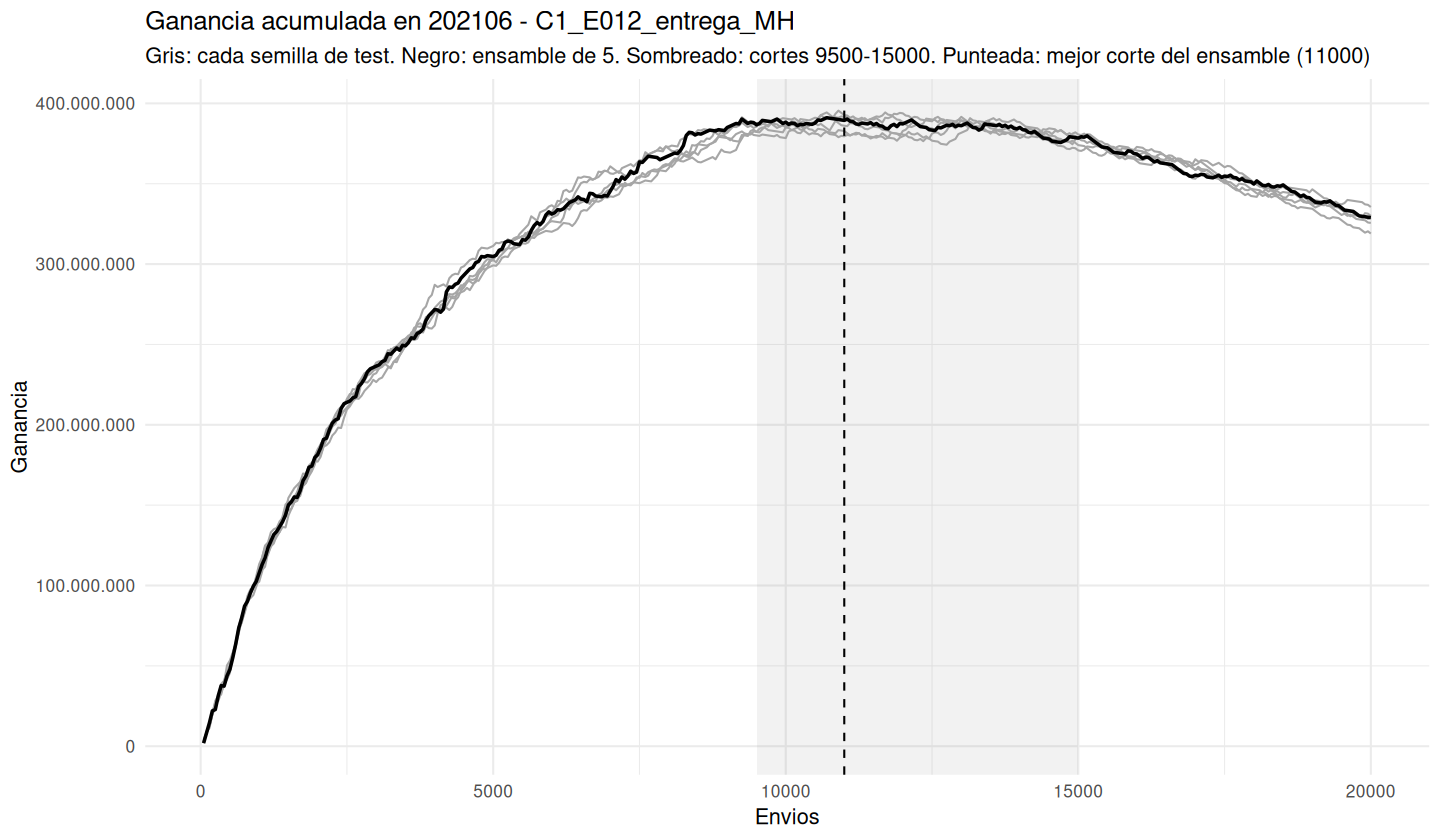

In [15]:
faltan_hp <- anyNA(unlist(PARAM$mejores_hiperparametros))
if (faltan_hp) stop("Falta definir los mejores hiperparametros en la celda 1.2")

# meses en el mismo orden que en la experimentacion (asi las probabilidades coinciden)
dataset <- leer_meses_fst(archivo_fe, sort(unique(c(PARAM$train_test, PARAM$test, PARAM$train_final, PARAM$future))))
dataset[, clase01 := ifelse(clase_ternaria %in% c("BAJA+1", "BAJA+2"), 1L, 0L)]
campos <- setdiff(colnames(dataset), c("clase_ternaria", "clase01", "azar", "training"))
dir.create(file.path(carpeta_exp, "test"), showWarnings = FALSE)

if (PARAM$test_n_semillas > 0) {
  arch_test <- file.path(carpeta_exp, "test", sprintf("prob_test_%02d.csv", seq_len(PARAM$test_n_semillas)))
  filas_te <- which(dataset$foto_mes %in% PARAM$test)
  faltan <- which(!file.exists(arch_test))

  if (length(faltan)) {
    dtest_train <- armar_dtrain(dataset, which(dataset$foto_mes %in% PARAM$train_test), campos)
    mtest <- armar_matriz(dataset, filas_te, campos)
    for (k in faltan) {
      t0 <- Sys.time()
      param_k <- modifyList(param_final, list(seed = PARAM$semillas_20[k], data_random_seed = PARAM$semilla_primigenia))
      modelo <- lgb.train(data = dtest_train, params = param_k)
      fwrite(data.table(numero_de_cliente = dataset$numero_de_cliente[filas_te], prob = predict(modelo, mtest)), arch_test[k])
      fwrite(lgb.importance(modelo), file.path(carpeta_exp, "test", sprintf("impo_test_%02d.txt", k)), sep = "\t")
      rm(modelo); gc(full = TRUE, verbose = FALSE)
      cat(sprintf("Test semilla %d de %d lista en %.1f min\n", k, PARAM$test_n_semillas,
                  as.numeric(difftime(Sys.time(), t0, units = "mins"))))
    }
    rm(dtest_train, mtest); gc(full = TRUE, verbose = FALSE)
  }

  # ganancia por corte de cada semilla y del ensamble
  tt <- dataset[filas_te, list(numero_de_cliente, clase_ternaria)]
  for (k in seq_len(PARAM$test_n_semillas)) {
    p <- fread(arch_test[k])
    tt[p, on = "numero_de_cliente", (sprintf("s%02d", k)) := i.prob]
  }
  cols_t <- sprintf("s%02d", seq_len(PARAM$test_n_semillas))
  tt[, ensamble := rowMeans(.SD), .SDcols = cols_t]
  ganancia_cortes <- function(prob) cumsum(ifelse(tt$clase_ternaria[order(-prob)] == "BAJA+2", 1072500, -27500))[PARAM$cortes]
  tb_test <- data.table(envios = PARAM$cortes)
  for (cc in c(cols_t, "ensamble")) tb_test[, (cc) := ganancia_cortes(tt[[cc]])]
  tb_test[, promedio_semillas := rowMeans(.SD), .SDcols = cols_t]
  fwrite(tb_test, file.path(carpeta_exp, "test", "ganancia_test_cortes.csv"))

  options(scipen = 999)
  cat("\nGanancia en", PARAM$test, "por corte (cada semilla, su promedio y el ensamble):\n")
  print(tb_test)
  cat("Mejor corte del ensamble:", tb_test[which.max(ensamble), envios], "\n")

  # curva de ganancia acumulada (cada 50 envios hasta 20.000): una por semilla y la del ensamble
  pos <- seq(50L, min(20000L, nrow(tt)), by = 50L)
  curvas <- rbindlist(lapply(c(cols_t, "ensamble"), function(cc) {
    g <- cumsum(ifelse(tt$clase_ternaria[order(-tt[[cc]])] == "BAJA+2", 1072500, -27500))
    data.table(serie = cc, envios = pos, ganancia = g[pos])
  }))
  fwrite(curvas, file.path(carpeta_exp, "test", "curva_ganancia_test.csv"))
  corte_ens <- tb_test[which.max(ensamble), envios]

  gra <- ggplot() +
    annotate("rect", xmin = min(PARAM$cortes), xmax = max(PARAM$cortes), ymin = -Inf, ymax = Inf, alpha = 0.08) +
    geom_line(data = curvas[serie != "ensamble"], aes(x = envios, y = ganancia, group = serie), color = "grey65") +
    geom_line(data = curvas[serie == "ensamble"], aes(x = envios, y = ganancia), color = "black", linewidth = 1) +
    geom_vline(xintercept = corte_ens, linetype = "dashed") +
    scale_y_continuous(labels = function(x) format(x, big.mark = ".", decimal.mark = ",", scientific = FALSE)) +
    labs(title = paste0("Ganancia acumulada en ", PARAM$test, " - ", PARAM$experimento),
         subtitle = paste0("Gris: cada semilla de test. Negro: ensamble de ", length(cols_t),
                           ". Sombreado: cortes ", min(PARAM$cortes), "-", max(PARAM$cortes),
                           ". Punteada: mejor corte del ensamble (", corte_ens, ")"),
         x = "Envios", y = "Ganancia") +
    theme_minimal(base_size = 13)
  ggsave(file.path(carpeta_exp, "test", "curva_ganancia_test.png"), gra, width = 12, height = 7)
  options(repr.plot.width = 12, repr.plot.height = 7)
  print(gra)
  rm(curvas, gra, pos)

  # importancia de variables del test: promedio de las semillas (registro)
  arch_imp_t <- list.files(file.path(carpeta_exp, "test"), pattern = "^impo_test_[0-9]+\\.txt$", full.names = TRUE)
  if (length(arch_imp_t)) {
    imp_t <- rbindlist(lapply(arch_imp_t, fread))
    imp_t <- imp_t[, list(Gain = sum(Gain) / length(arch_imp_t), Frequency = sum(Frequency) / length(arch_imp_t),
                          modelos = .N), by = Feature][order(-Gain)]
    fwrite(imp_t, file.path(carpeta_exp, "test", "impo_test.txt"), sep = "\t")
    cat("Importancia del test (promedio de", length(arch_imp_t), "modelos):", file.path(carpeta_exp, "test", "impo_test.txt"), "\n")
  }
  rm(tt, filas_te, p)
} else cat("Test en 202106 omitido (PARAM$test_n_semillas = 0)\n")

# 2. Producción

## 2.1 Dataset final
Del dataset ya leído en 1.3 se toman los meses de entrenamiento (202103 a 202106) y el mes a predecir (202108). La clase está en binario (BAJA+1 y BAJA+2 valen 1, CONTINUA vale 0) y se usan todas las columnas como variables salvo la clase.

In [16]:
PARAM$semillas <- PARAM$semillas_20[seq_len(PARAM$n_semillas)]

filas_train  <- which(dataset$foto_mes %in% PARAM$train_final)
filas_future <- which(dataset$foto_mes %in% PARAM$future)
ids_future   <- dataset$numero_de_cliente[filas_future]

print(dataset[filas_train, .N, keyby = list(foto_mes, clase_ternaria)])
cat("A predecir:", length(filas_future), "clientes de", PARAM$future, "| variables:", length(campos), "\n")

# datos en el formato de LightGBM: se arman una sola vez y sirven para las 20 semillas
dtrain  <- armar_dtrain(dataset, filas_train, campos)
mfuture <- armar_matriz(dataset, filas_future, campos)
rm(dataset, filas_train, filas_future)
gc(full = TRUE, verbose = FALSE)

Key: <foto_mes, clase_ternaria>
    foto_mes clase_ternaria      N
       <int>         <char>  <int>
 1:   202103         BAJA+1   1019
 2:   202103         BAJA+2    960
 3:   202103       CONTINUA 160921
 4:   202104         BAJA+1    964
 5:   202104         BAJA+2   1139
 6:   202104       CONTINUA 161181
 7:   202105         BAJA+1   1143
 8:   202105         BAJA+2    870
 9:   202105       CONTINUA 161755
10:   202106         BAJA+1    874
11:   202106         BAJA+2   1098
12:   202106       CONTINUA 162142
A predecir: 164647 clientes de 202108 | variables: 762 


,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2511434,134.2,4493285,240.0,4493285,240.0
Vcells,130731235,997.5,1313963568,10024.8,1378301229,10515.7


## 2.2 LightGBM finales
20 modelos con los mismos hiperparámetros; lo único que cambia es la semilla. Cada uno entrena con todos los datos de 202103 a 202106 y predice la probabilidad de baja de cada cliente en 202108. La probabilidad de cada semilla se guarda en `probabilidades/`; si ya existe, no se vuelve a entrenar.

De cada modelo también se guarda la importancia de variables (`impo_..._NN.txt`, de `lgb.importance`), y al final se arma `impo.txt` con el promedio de los modelos finales.

In [ ]:
arch_prob <- file.path(carpeta_exp, "probabilidades", sprintf("prob_%s_%02d.csv", PARAM$experimento, seq_along(PARAM$semillas)))

for (k in seq_along(PARAM$semillas)) {
  if (file.exists(arch_prob[k])) { cat("Semilla", PARAM$semillas[k], "ya calculada\n"); next }
  t0 <- Sys.time()
  param_k <- modifyList(param_final, list(seed = PARAM$semillas[k], data_random_seed = PARAM$semilla_primigenia))
  modelo <- lgb.train(data = dtrain, params = param_k)
  fwrite(data.table(numero_de_cliente = ids_future, prob = predict(modelo, mfuture)), arch_prob[k])
  fwrite(lgb.importance(modelo), sub("\\.csv$", ".txt", sub("prob_", "impo_", arch_prob[k])), sep = "\t")
  cat(sprintf("Semilla %d (%d de %d) lista en %.1f min | faltan %d\n", PARAM$semillas[k], k, length(PARAM$semillas),
              as.numeric(difftime(Sys.time(), t0, units = "mins")), sum(!file.exists(arch_prob))))
  # csv del modelo recien terminado
  p <- fread(arch_prob[k]); print(head(p[order(-prob)], 5)); rm(p)
  rm(modelo)
  gc(full = TRUE, verbose = FALSE)
}
rm(dtrain, mfuture)
gc(full = TRUE, verbose = FALSE)

# importancia de variables: promedio de los modelos finales (Gain y Frequency; si una variable
# no se uso en un modelo cuenta como 0 en ese modelo)
arch_imp <- list.files(file.path(carpeta_exp, "probabilidades"), pattern = "^impo_.*\\.txt$", full.names = TRUE)
if (length(arch_imp)) {
  imp <- rbindlist(lapply(arch_imp, fread))
  imp_prom <- imp[, list(Gain = sum(Gain) / length(arch_imp), Frequency = sum(Frequency) / length(arch_imp),
                         modelos = .N), by = Feature][order(-Gain)]
  fwrite(imp_prom, file.path(carpeta_exp, "impo.txt"), sep = "\t")
  cat("Importancia de variables (promedio de", length(arch_imp), "modelos finales) en", file.path(carpeta_exp, "impo.txt"), "\n")
  print(head(imp_prom, 30))
}


## 2.3 Clasificación
Ensambles: para cada cliente se promedian las probabilidades de los primeros 5, 10, 15 y 20 modelos y se ordena de mayor a menor. De cada ensamble se generan los archivos para Zulip con los primeros 9.500, 10.000, …, 15.000 clientes del ranking.

```
zulip_cortes/ens05/<corte>/<experimento>_ens05_c<corte>.csv   (y ens10, ens15, ens20)
```

In [18]:
arch_prob <- file.path(carpeta_exp, "probabilidades", sprintf("prob_%s_%02d.csv", PARAM$experimento, seq_along(PARAM$semillas)))

ensambles <- list()
for (n in PARAM$bloques) {
  tb <- data.table(numero_de_cliente = ids_future, foto_mes = PARAM$future)
  for (k in seq_len(n)) {
    p <- fread(arch_prob[k])
    stopifnot(nrow(p) == nrow(tb), setequal(p$numero_de_cliente, tb$numero_de_cliente))
    tb[p, on = "numero_de_cliente", (sprintf("prob_%02d", k)) := i.prob]
  }
  tb[, prob := rowMeans(.SD), .SDcols = sprintf("prob_%02d", seq_len(n))]
  setorder(tb, -prob)

  etiqueta <- sprintf("ens%02d", n)
  fwrite(tb, file.path(carpeta_exp, paste0("prediccion_", PARAM$experimento, "_", etiqueta, "_", PARAM$future, ".csv")))
  for (corte in PARAM$cortes) {
    carpeta <- file.path(carpeta_exp, "zulip_cortes", etiqueta, corte)
    dir.create(carpeta, recursive = TRUE, showWarnings = FALSE)
    escribir_zulip(tb$numero_de_cliente[seq_len(corte)],
                   file.path(carpeta, sprintf("%s_%s_c%d.csv", sub("_entrega$", "", PARAM$experimento), etiqueta, corte)))
  }
  cat("Ensamble de", n, "modelos ->", file.path(carpeta_exp, "zulip_cortes", etiqueta), "\n")
  ensambles[[etiqueta]] <- tb[, list(numero_de_cliente, prob)]
}

Ensamble de 5 modelos -> /home/ds/buckets/b1/exp/C1_E012_entrega_MH/zulip_cortes/ens05 
Ensamble de 10 modelos -> /home/ds/buckets/b1/exp/C1_E012_entrega_MH/zulip_cortes/ens10 
Ensamble de 15 modelos -> /home/ds/buckets/b1/exp/C1_E012_entrega_MH/zulip_cortes/ens15 
Ensamble de 20 modelos -> /home/ds/buckets/b1/exp/C1_E012_entrega_MH/zulip_cortes/ens20 


# 3. Zulip
Archivo final para la entrega: el ensamble de los **20 modelos**, cortado en `PARAM$envios` clientes, sin encabezado y como enteros. Se sube por mensaje privado a `@competencia-uno`.

El archivo es el mismo que aparece en `zulip_cortes/ens20/12000/`.

In [19]:
PARAM$envios <- 12000   # cantidad de clientes a realizar envios

archivo_zulip <- file.path(carpeta_exp, "zulip", sprintf("C1_E012_ensamble_20S_%d.csv", PARAM$envios))
stopifnot(!is.na(PARAM$envios), PARAM$envios >= 9500L, PARAM$envios <= 15000L)

final <- ensambles[["ens20"]]          # ya ordenado por probabilidad promedio de los 20 modelos
escribir_zulip(final$numero_de_cliente[seq_len(PARAM$envios)], archivo_zulip)

control <- readLines(archivo_zulip)
cat("Archivo para Zulip:", archivo_zulip, "\n")
cat("Filas:", length(control), "| ids distintos:", uniqueN(control), "\n")
head(control)

Archivo para Zulip: /home/ds/buckets/b1/exp/C1_E012_entrega_MH/zulip/C1_E012_ensamble_20S_12000.csv 
Filas: 12000 | ids distintos: 12000 


[1] "60622229" "31028886" "23214907" "42738466" "52878216" "31959546"